# Dónde poner la lupa, focalización sectorial de la formalización laboral

Proyecto Final Integrador, Diplomado en Ciencia de Datos y Análisis Avanzado (UTN BA)
Bernardita Viera y Renzo Mirabella

Fuente INDEC, Encuesta Permanente de Hogares, microdatos del 1.er trimestre de 2026 (base individual). Las decisiones de datos y modelado están registradas en `data_log.md`.

## 1) Configuración y librerías

In [1]:
# =============================================================================
# 1) Librerías y parámetros generales
# =============================================================================
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

SEED = 42
K = 0.20           # la lupa cubre el 20 % de los ocupados (medido con PONDERA)
N_FOLDS = 5
B_BOOTSTRAP = 500

DATA_DIR = Path('data')        # en Colab, subir el .xlsx a data/ o montar Drive y cambiar esta ruta
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)
ARCHIVO = 'usu_individual_T126'

## 2) Carga de datos y validación contra INDEC

Se carga la base individual, se arma el target a partir de `EMPLEO` y se verifica que la tasa ponderada replique el 44,2 % publicado.

In [2]:
# =============================================================================
# 2) Carga (la primera vez lee el .xlsx y guarda una copia .parquet)
# =============================================================================
def cargar_eph():
    cache = DATA_DIR / f'{ARCHIVO}.parquet'
    if cache.exists():
        return pd.read_parquet(cache)
    ruta = DATA_DIR / f'{ARCHIVO}.xlsx'
    if not ruta.exists():
        raise FileNotFoundError(f'No se encontró {ruta} (ver README)')
    eph = pd.read_excel(ruta)
    eph.to_parquet(cache)
    return eph


eph = cargar_eph()
print(f'Base individual: {eph.shape[0]:,} personas y {eph.shape[1]} variables')

duplicados = eph.duplicated(['CODUSU', 'NRO_HOGAR', 'COMPONENTE']).sum()
ocupados = eph[eph['ESTADO'] == 1]
print('Registros duplicados (vivienda, hogar, componente):', duplicados)
print(f'Ocupados: {len(ocupados):,}')
print(ocupados['EMPLEO'].value_counts().sort_index()
      .rename({1: 'formal', 2: 'informal', 9: 'sin dato'}).to_string())

datos = ocupados[ocupados['EMPLEO'].isin([1, 2])].copy()
datos['informal'] = (datos['EMPLEO'] == 2).astype(int)
datos['wy'] = datos['informal'] * datos['PONDERA']
poblacion = datos['PONDERA'].sum()

TASA = datos['wy'].sum() / poblacion
print(f'\nPoblación de análisis: {len(datos):,} ocupados ({poblacion / 1e6:.1f} millones expandidos)')
print(f'Tasa de informalidad ponderada: {TASA:.1%} (INDEC publica 44,2 %)')
print(f'Tasa sin ponderar: {datos["informal"].mean():.1%}')
assert duplicados == 0
assert abs(TASA - 0.442) < 0.001

Base individual: 43,739 personas y 234 variables
Registros duplicados (vivienda, hogar, componente): 0
Ocupados: 19,573
EMPLEO
formal      10762
informal     8798
sin dato       13

Población de análisis: 19,560 ocupados (13.5 millones expandidos)
Tasa de informalidad ponderada: 44.2% (INDEC publica 44,2 %)
Tasa sin ponderar: 45.0%


## 3) Calidad de datos, códigos especiales y outliers

La base no tiene celdas vacías, los faltantes vienen como códigos numéricos. Se cuentan sobre los ocupados y se define el tratamiento de cada uno.

In [3]:
# =============================================================================
# 3) Códigos especiales y outliers
# =============================================================================
print('Celdas vacías en las variables usadas:',
      int(ocupados[['EMPLEO', 'CAT_OCUP', 'PP04A', 'PP04B_COD', 'PP04C', 'PP04D_COD',
                    'CH04', 'CH06', 'NIVEL_ED', 'REGION', 'PONDERA']].isna().sum().sum()))

calificacion_cno = ocupados['PP04D_COD'].astype('Int64').astype(str).str.zfill(5).str[4]
CODIGOS = [  # (variable, código, significado, máscara, tratamiento)
    ('EMPLEO', '9', 'Sin dato de formalidad', ocupados['EMPLEO'] == 9, 'Se excluye (no hay target)'),
    ('PP04C', '0', 'No corresponde: casas particulares', ocupados['PP04C'] == 0, 'Categoría propia'),
    ('PP04C', '99', 'No sabe el tamaño', ocupados['PP04C'] == 99, 'Se usa PP04C99 (pregunta de respaldo)'),
    ('PP04C99', '1-3', '...pero sabe el tramo grueso', ocupados['PP04C99'].isin([1, 2, 3]), 'Tramo NS: hasta 5 / 6-40 / +40'),
    ('PP04C99', '9', '...y tampoco sabe el tramo', ocupados['PP04C99'] == 9, 'Categoría "Sin dato"'),
    ('PP04B_COD', '9999', 'Actividad no especificada', ocupados['PP04B_COD'] == 9999, 'Rama "Sin dato"'),
    ('PP04D_COD', '5.° díg. 6-9', 'Calificación sin especificar', ~calificacion_cno.isin(list('1234')), 'Calificación "Sin dato"'),
    ('P21', '-9', 'No responde el ingreso', ocupados['P21'] == -9, 'Variable excluida del modelo'),
]
tabla_codigos = pd.DataFrame([
    {'variable': v, 'código': c, 'significado': s, 'casos': int(m.sum()),
     '% ocupados': m.mean(), 'tratamiento': t}
    for v, c, s, m, t in CODIGOS
])
tabla_codigos.to_csv(RESULTS_DIR / 'tabla_codigos_especiales.csv', index=False)
display(tabla_codigos.style.format({'% ocupados': '{:.1%}'}))


def resumen_outliers(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    techo = q3 + 1.5 * (q3 - q1)
    return {'casos': len(serie), 'mínimo': serie.min(), 'mediana': serie.median(),
            'p99': serie.quantile(0.99), 'máximo': serie.max(),
            'techo IQR': techo, 'casos sobre el techo': int((serie > techo).sum())}


ingreso = ocupados.loc[ocupados['P21'] > 0, 'P21']
tabla_outliers = pd.DataFrame({
    'Ingreso ocupación principal (P21 > 0)': resumen_outliers(ingreso),
    'Edad (CH06)': resumen_outliers(ocupados['CH06']),
}).T
tabla_outliers.to_csv(RESULTS_DIR / 'tabla_outliers.csv')
print(f'Ocupados con ingreso 0: {(ocupados["P21"] == 0).sum():,}')
display(tabla_outliers.style.format('{:,.0f}'))

Celdas vacías en las variables usadas: 0


,variable,código,significado,casos,% ocupados,tratamiento
0,EMPLEO,9,Sin dato de formalidad,13,0.1%,Se excluye (no hay target)
1,PP04C,0,No corresponde: casas particulares,1314,6.7%,Categoría propia
2,PP04C,99,No sabe el tamaño,2609,13.3%,Se usa PP04C99 (pregunta de respaldo)
3,PP04C99,1-3,...pero sabe el tramo grueso,1334,6.8%,Tramo NS: hasta 5 / 6-40 / +40
4,PP04C99,9,...y tampoco sabe el tramo,1275,6.5%,"Categoría ""Sin dato"""
5,PP04B_COD,9999,Actividad no especificada,91,0.5%,"Rama ""Sin dato"""
6,PP04D_COD,5.° díg. 6-9,Calificación sin especificar,19,0.1%,"Calificación ""Sin dato"""
7,P21,-9,No responde el ingreso,3726,19.0%,Variable excluida del modelo


Ocupados con ingreso 0: 399


,casos,mínimo,mediana,p99,máximo,techo IQR,casos sobre el techo
Ingreso ocupación principal (P21 > 0),"15,448","5,000","800,000","4,000,000","40,000,000","2,325,000",835
Edad (CH06),"19,573",10,41,73,99,81,19


## 4) Variables excluidas por fuga

Se compara la exactitud de clasificar con una sola variable (clase mayoritaria de cada categoría) contra la exactitud trivial, para las variables que forman parte de la definición de informalidad y para los predictores elegidos.

In [4]:
# =============================================================================
# 4) Exclusiones por fuga y por decisión
# =============================================================================
EXCLUIDAS_FUGA = {
    'SECTOR': 'Sector formal/informal (derivado del mismo indicador)',
    'PP07G1': 'Vacaciones pagas', 'PP07G2': 'Aguinaldo', 'PP07G3': 'Días pagos por enfermedad',
    'PP07G4': 'Obra social', 'PP07G_59': 'Ninguno de los beneficios',
    'PP07H': 'Descuento jubilatorio', 'PP07I': 'Aporta por sí mismo',
    'PP07I2': 'Registración (asalariados)', 'PP07I3': 'Registración (asalariados)',
    'PP07I4': 'Registración (asalariados)', 'PP07L': 'Registración (asalariados)',
    'PP05I': 'Registración del negocio (independientes)', 'PP05J': 'Registración (independientes)',
    'PP05K': 'Registración (independientes)',
}
EXCLUIDAS_DECISION = {
    'P21': 'Ingreso de la ocupación principal: en parte consecuencia de la informalidad',
    'PP3E_TOT': 'Horas trabajadas: condición del puesto',
    'PP3F_TOT': 'Horas en otras ocupaciones',
}
PREDICTORES_ORIGINALES = ['CAT_OCUP', 'PP04A', 'PP04B_COD', 'PP04C', 'PP04D_COD',
                          'CH04', 'CH06', 'NIVEL_ED', 'REGION']
assert not set(PREDICTORES_ORIGINALES) & (set(EXCLUIDAS_FUGA) | set(EXCLUIDAS_DECISION))


def exactitud_una_variable(sub, col, min_casos=30):
    """Exactitud de clasificar a cada persona con la clase mayoritaria de su categoría."""
    t = sub.groupby(col)['informal'].agg(['sum', 'size'])
    grandes = t['size'] >= min_casos
    aciertos = np.maximum(t['sum'], t['size'] - t['sum'])[grandes].sum()
    resto = sub[sub[col].isin(t.index[~grandes])]['informal']
    aciertos += max(resto.sum(), len(resto) - resto.sum())
    return aciertos / len(sub)


def exactitud_trivial(sub):
    return max(sub['informal'].mean(), 1 - sub['informal'].mean())


asalariados = datos[datos['CAT_OCUP'] == 3]
independientes = datos[datos['CAT_OCUP'].isin([1, 2])]
roles = ([(c, m, 'excluida (fuga)') for c, m in EXCLUIDAS_FUGA.items()]
         + [(c, '', 'predictor') for c in PREDICTORES_ORIGINALES])
tabla_fuga = pd.DataFrame([
    {'variable': c, 'rol': rol, 'motivo': m,
     'exactitud asalariados': exactitud_una_variable(asalariados, c),
     'exactitud independientes': exactitud_una_variable(independientes, c)}
    for c, m, rol in roles
]).round(3)
print(f'Exactitud trivial: asalariados {exactitud_trivial(asalariados):.3f}, '
      f'independientes {exactitud_trivial(independientes):.3f}')
tabla_fuga.to_csv(RESULTS_DIR / 'tabla_exclusiones_fuga.csv', index=False)
tabla_fuga

Exactitud trivial: asalariados 0.624, independientes 0.628


,variable,rol,motivo,exactitud asalariados,exactitud independientes
0,SECTOR,excluida (fuga),Sector formal/informal (derivado del mismo ind...,0.815,1.000
1,PP07G1,excluida (fuga),Vacaciones pagas,0.962,0.628
2,PP07G2,excluida (fuga),Aguinaldo,0.970,0.628
3,PP07G3,excluida (fuga),Días pagos por enfermedad,0.969,0.628
4,PP07G4,excluida (fuga),Obra social,0.979,0.628
5,PP07G_59,excluida (fuga),Ninguno de los beneficios,0.946,0.628
6,PP07H,excluida (fuga),Descuento jubilatorio,1.000,0.628
7,PP07I,excluida (fuga),Aporta por sí mismo,0.997,0.628
8,PP07I2,excluida (fuga),Registración (asalariados),0.894,0.628
9,PP07I3,excluida (fuga),Registración (asalariados),0.814,0.628


## 5) Ingeniería de variables

Rama por sección CAES, tamaño en tramos con la pregunta de respaldo `PP04C99`, calificación desde la CNO, edad en tramos, y las dos vistas de evaluación (`segmento` y `alcanzable`).

In [5]:
# =============================================================================
# 5) Ingeniería de variables
# =============================================================================
SECCIONES = [  # (división desde, hasta, sección CAES-Mercosur)
    (1, 3, 'A Agro y pesca'), (5, 9, 'B Minería'), (10, 33, 'C Industria'),
    (35, 35, 'D Electricidad y gas'), (36, 39, 'E Agua y residuos'), (40, 43, 'F Construcción'),
    (45, 48, 'G Comercio'), (49, 53, 'H Transporte'), (55, 56, 'I Alojamiento y gastronomía'),
    (58, 63, 'J Información y comunicación'), (64, 66, 'K Finanzas'), (68, 68, 'L Inmobiliarias'),
    (69, 75, 'M Profesionales'), (77, 82, 'N Servicios de apoyo'), (83, 84, 'O Administración pública'),
    (85, 85, 'P Enseñanza'), (86, 88, 'Q Salud'), (90, 93, 'R Arte y recreación'),
    (94, 96, 'S Otros servicios'), (97, 98, 'T Casas particulares'), (99, 99, 'U Organismos extraterritoriales'),
]


def seccion(codigo):
    if pd.isna(codigo) or codigo == 9999:
        return 'Sin dato'
    division = codigo if codigo < 100 else codigo // 100  # 101 -> '0101' -> división 01
    for desde, hasta, nombre in SECCIONES:
        if desde <= division <= hasta:
            return nombre
    return 'Sin dato'


def tramo_tamano(c, c99):
    if c == 0:
        return 'Casas particulares'
    if c == 99:
        return {1: 'NS: hasta 5', 2: 'NS: 6 a 40', 3: 'NS: más de 40'}.get(c99, 'Sin dato')
    if c == 1:
        return '1 persona'
    if c <= 5:
        return '2 a 5'
    if c == 6:
        return '6 a 10'
    if c <= 8:
        return '11 a 40'
    if c == 9:
        return '41 a 100'
    if c <= 12:
        return 'Más de 100'
    return 'Sin dato'


TAMANO_REGLA = {
    '1 persona': 'Hasta 5', '2 a 5': 'Hasta 5', 'NS: hasta 5': 'Hasta 5',
    '6 a 10': '6 a 40', '11 a 40': '6 a 40', 'NS: 6 a 40': '6 a 40',
    '41 a 100': 'Más de 40', 'Más de 100': 'Más de 40', 'NS: más de 40': 'Más de 40',
    'Casas particulares': 'Casas particulares', 'Sin dato': 'Sin dato',
}
CALIFICACION = {'1': 'Profesional', '2': 'Técnica', '3': 'Operativa', '4': 'No calificada'}
NIVEL_ED = {7: '0 Sin instrucción', 1: '1 Primario incompleto', 2: '2 Primario completo',
            3: '3 Secundario incompleto', 4: '4 Secundario completo', 5: '5 Superior incompleto',
            6: '6 Superior completo'}
REGION = {1: 'GBA', 40: 'NOA', 41: 'NEA', 42: 'Cuyo', 43: 'Pampeana', 44: 'Patagonia'}
CAT_OCUP = {1: 'Patrón', 2: 'Cuenta propia', 3: 'Asalariado', 4: 'Trabajador familiar'}
AMBITO = {1: 'Estatal', 2: 'Privado', 3: 'Otro'}

d = datos
d['rama'] = d['PP04B_COD'].map(seccion)
d['tamano'] = [tramo_tamano(c, c99) for c, c99 in zip(d['PP04C'], d['PP04C99'])]
d['tamano_regla'] = d['tamano'].map(TAMANO_REGLA)
cno = d['PP04D_COD'].astype('Int64').astype(str).str.zfill(5)
d['calificacion'] = cno.str[4].map(CALIFICACION).fillna('Sin dato')
d['caracter'] = cno.str[:2]
d['edad'] = pd.cut(d['CH06'], [-1, 17, 24, 34, 49, 59, 64, 200],
                   labels=['10-17', '18-24', '25-34', '35-49', '50-59', '60-64', '65+']).astype(str)
d['sexo'] = d['CH04'].map({1: 'Varón', 2: 'Mujer'})
d['nivel_ed'] = d['NIVEL_ED'].map(NIVEL_ED).fillna('Sin dato')
d['region'] = d['REGION'].map(REGION)
d['cat_ocup'] = d['CAT_OCUP'].map(CAT_OCUP)
d['ambito'] = d['PP04A'].map(AMBITO).fillna('Sin dato')

d['segmento'] = d['rama'] + ' | ' + d['tamano_regla'] + ' | ' + d['region']
d['alcanzable'] = ((d['cat_ocup'] == 'Asalariado') & (d['ambito'] == 'Privado')
                   & (d['tamano'] != 'Casas particulares'))

FEATURES = ['cat_ocup', 'ambito', 'rama', 'tamano', 'calificacion', 'sexo', 'edad', 'nivel_ed', 'region']
assert d[FEATURES].notna().all().all()
print('Categorías por variable:', d[FEATURES].nunique().to_dict())
print('Segmentos rama × tamaño × región con casos:', d['segmento'].nunique())
print(f'Asalariados privados (sin casas particulares): '
      f'{d.loc[d["alcanzable"], "PONDERA"].sum() / poblacion:.1%} de los ocupados')

Categorías por variable: {'cat_ocup': 4, 'ambito': 3, 'rama': 22, 'tamano': 11, 'calificacion': 5, 'sexo': 2, 'edad': 7, 'nivel_ed': 7, 'region': 6}
Segmentos rama × tamaño × región con casos: 460
Asalariados privados (sin casas particulares): 48.8% de los ocupados


In [6]:
# =============================================================================
# 5.1) Verificaciones de los códigos
# =============================================================================
cod = d['PP04B_COD']
digitos = np.select([cod < 100, cod < 1000], ['2 dígitos (división)', '3 dígitos (perdió el 0 inicial)'],
                    '4 dígitos')
print(pd.Series(digitos).value_counts().to_string())
sin_seccion = int(((d['rama'] == 'Sin dato') & (cod != 9999)).sum())
print(f'Códigos de rama válidos sin sección: {sin_seccion}')
assert sin_seccion == 0
print(f'Códigos CNO de 4 dígitos (se completan a 5): {(d["PP04D_COD"] < 10000).sum():,}')

print()
print(pd.crosstab(d['rama'] == 'T Casas particulares', d['tamano'] == 'Casas particulares'))
print()
print(pd.crosstab(d['PP04C'] == 99, d['PP04C99'] > 0, rownames=['PP04C = 99'], colnames=['responde PP04C99']))
assert ((d['PP04C'] != 99) & (d['PP04C99'] > 0)).sum() == 0

4 dígitos                          19213
3 dígitos (perdió el 0 inicial)      315
2 dígitos (división)                  32


Códigos de rama válidos sin sección: 0
Códigos CNO de 4 dígitos (se completan a 5): 897

tamano  False  True 
rama                
False   18227      0
True       19   1314

responde PP04C99  False  True 
PP04C = 99                    
False             16953      0
True                  0   2607


In [7]:
# =============================================================================
# 5.2) Diccionario de las variables del modelo
# =============================================================================
DICCIONARIO = [  # (variable del modelo, variable EPH, descripción, tipo, rol)
    ('informal', 'EMPLEO', 'Condición de formalidad (1 = informal)', 'Binaria', 'Target'),
    ('cat_ocup', 'CAT_OCUP', 'Categoría ocupacional', 'Categórica', 'Predictor'),
    ('ambito', 'PP04A', 'Ámbito del establecimiento (estatal / privado / otro)', 'Categórica', 'Predictor'),
    ('rama', 'PP04B_COD', 'Rama de actividad, sección CAES-Mercosur', 'Categórica', 'Predictor'),
    ('tamano', 'PP04C + PP04C99', 'Tamaño del establecimiento en tramos', 'Ordinal', 'Predictor'),
    ('calificacion', 'PP04D_COD', 'Calificación de la tarea (5.° dígito CNO 2001)', 'Ordinal', 'Predictor'),
    ('sexo', 'CH04', 'Sexo', 'Binaria', 'Predictor / auditar'),
    ('edad', 'CH06', 'Tramo de edad', 'Ordinal', 'Predictor / auditar'),
    ('nivel_ed', 'NIVEL_ED', 'Máximo nivel educativo', 'Ordinal', 'Predictor'),
    ('region', 'REGION', 'Región estadística', 'Categórica', 'Predictor / auditar'),
    ('caracter', 'PP04D_COD', 'Carácter ocupacional (2 primeros dígitos CNO)', 'Categórica', 'Variante del paso 9'),
    ('PONDERA', 'PONDERA', 'Factor de expansión', 'Numérica', 'Peso de las métricas'),
    ('CODUSU', 'CODUSU', 'Identificador de vivienda', 'Clave', 'Agrupa la partición'),
]
diccionario = pd.DataFrame(DICCIONARIO, columns=['variable', 'origen EPH', 'descripción', 'tipo', 'rol'])
diccionario['categorías'] = [d[v].nunique() if v in FEATURES + ['caracter'] else None
                             for v in diccionario['variable']]
diccionario.to_csv(RESULTS_DIR / 'diccionario_variables.csv', index=False)
diccionario

,variable,origen EPH,descripción,tipo,rol,categorías
0,informal,EMPLEO,Condición de formalidad (1 = informal),Binaria,Target,NaN
1,cat_ocup,CAT_OCUP,Categoría ocupacional,Categórica,Predictor,4.0
2,ambito,PP04A,Ámbito del establecimiento (estatal / privado ...,Categórica,Predictor,3.0
3,rama,PP04B_COD,"Rama de actividad, sección CAES-Mercosur",Categórica,Predictor,22.0
4,tamano,PP04C + PP04C99,Tamaño del establecimiento en tramos,Ordinal,Predictor,11.0
5,calificacion,PP04D_COD,Calificación de la tarea (5.° dígito CNO 2001),Ordinal,Predictor,5.0
6,sexo,CH04,Sexo,Binaria,Predictor / auditar,2.0
7,edad,CH06,Tramo de edad,Ordinal,Predictor / auditar,7.0
8,nivel_ed,NIVEL_ED,Máximo nivel educativo,Ordinal,Predictor,7.0
9,region,REGION,Región estadística,Categórica,Predictor / auditar,6.0


## 6) EDA, tasas de informalidad ponderadas

Tasas por cada variable del modelo, todas con `PONDERA`.

In [8]:
# =============================================================================
# 6) Tasas ponderadas por variable
# =============================================================================
def tasa_por(df, col):
    g = df.groupby(col)
    return pd.DataFrame({
        'casos': g.size(),
        '% de ocupados': g['PONDERA'].sum() / df['PONDERA'].sum(),
        'tasa informal': g['wy'].sum() / g['PONDERA'].sum(),
    })


eda = {col: tasa_por(d, col) for col in FEATURES}
for col in ['tamano', 'calificacion', 'edad', 'cat_ocup']:
    print(f'\n{col}'); print(eda[col].round(3).to_string())
print('\nAsalariados por tamaño (grueso)')
print(tasa_por(d[d['cat_ocup'] == 'Asalariado'], 'tamano_regla').round(3).to_string())
pd.concat(eda, names=['variable', 'categoria']).to_csv(RESULTS_DIR / 'eda_tasas.csv')


tamano
                    casos  % de ocupados  tasa informal
tamano                                                 
1 persona            3879          0.198          0.680
11 a 40              2603          0.108          0.207
2 a 5                3961          0.193          0.645
41 a 100             1384          0.057          0.123
6 a 10               1513          0.071          0.426
Casas particulares   1314          0.066          0.775
Más de 100           2299          0.139          0.099
NS: 6 a 40            530          0.034          0.387
NS: hasta 5           171          0.011          0.627
NS: más de 40         633          0.054          0.219
Sin dato             1273          0.070          0.387

calificacion
               casos  % de ocupados  tasa informal
calificacion                                      
No calificada   3202          0.157          0.661
Operativa      11269          0.573          0.486
Profesional     1637          0.097          0

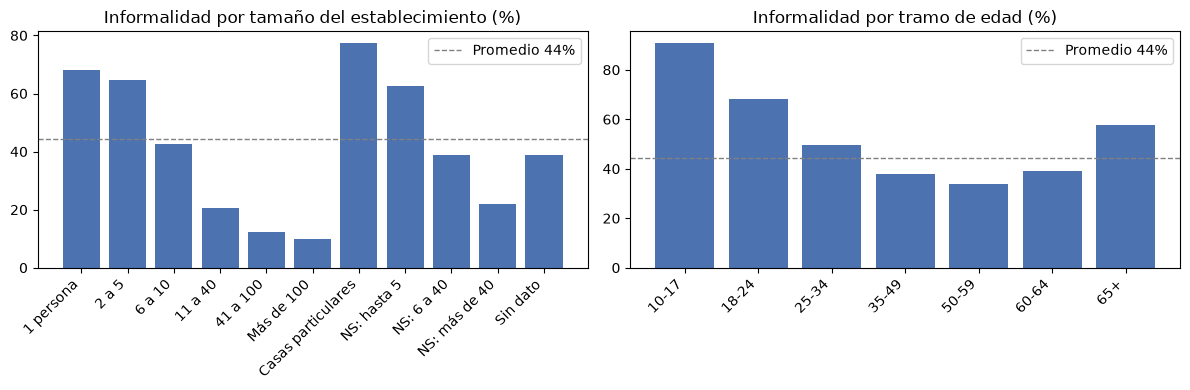

In [9]:
# =============================================================================
# 6.1) Figura 1, informalidad por tamaño del establecimiento y por edad
# =============================================================================
orden_tamano = ['1 persona', '2 a 5', '6 a 10', '11 a 40', '41 a 100', 'Más de 100',
                'Casas particulares', 'NS: hasta 5', 'NS: 6 a 40', 'NS: más de 40', 'Sin dato']
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
paneles = [(ejes[0], 'tamano', 'tamaño del establecimiento', orden_tamano),
           (ejes[1], 'edad', 'tramo de edad', None)]
for eje, col, titulo, orden in paneles:
    t = eda[col]['tasa informal']
    t = t.reindex(orden) if orden else t
    eje.bar(t.index, t.values * 100, color='#4C72B0')
    eje.axhline(TASA * 100, color='gray', ls='--', lw=1, label=f'Promedio {TASA:.0%}')
    eje.set_title(f'Informalidad por {titulo} (%)')
    plt.setp(eje.get_xticklabels(), rotation=45, ha='right')
    eje.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig1_eda.png', dpi=150)
plt.show()

## 7) Métricas ponderadas

Precisión, recall y F1 cuando la lupa cubre el 20 % del empleo, calculadas con `PONDERA`, con los empates en el corte incluidos de forma fraccional, y bootstrap por vivienda para los intervalos de confianza.

In [10]:
# =============================================================================
# 7) Funciones de métricas
# =============================================================================
def top_k(y, score, w, k=K):
    """Precisión y recall ponderados cuando la lupa cubre la fracción k de la población."""
    y, w = np.asarray(y), np.asarray(w, dtype=float)
    score = np.round(np.asarray(score, dtype=float), 10)
    positivo = w > 0
    t = (pd.DataFrame({'s': score[positivo], 'w': w[positivo], 'wy': (w * y)[positivo]})
         .groupby('s')[['w', 'wy']].sum()
         .iloc[::-1])
    foco = k * t['w'].sum()
    previo = t['w'].cumsum() - t['w']
    fraccion = ((foco - previo) / t['w']).clip(0, 1)
    seleccion_wy = (fraccion * t['wy']).sum()
    return seleccion_wy / foco, seleccion_wy / t['wy'].sum()


def score_segmento(score, w, segmento):
    """Reemplaza el score individual por el promedio ponderado de su segmento."""
    df = pd.DataFrame({'sw': np.asarray(score) * w, 'w': np.asarray(w), 'seg': np.asarray(segmento)})
    g = df.groupby('seg')
    return (g['sw'].transform('sum') / g['w'].transform('sum')).values


def f1(precision, recall):
    return 2 * precision * recall / (precision + recall)


def metricas(y, score, w):
    precision, recall = top_k(y, score, w)
    base = np.average(y, weights=w)
    return {'precision@20': precision, 'recall@20': recall, 'f1@20': f1(precision, recall),
            'lift@20': precision / base,
            'AUC': roc_auc_score(y, score, sample_weight=w),
            'PR-AUC': average_precision_score(y, score, sample_weight=w)}


def bootstrap_viviendas(y, scores, w, viviendas, B=B_BOOTSTRAP, seed=SEED):
    """Precisión @ 20 % de cada score en B réplicas pareadas que remuestrean viviendas."""
    rng = np.random.default_rng(seed)
    _, idx = np.unique(np.asarray(viviendas), return_inverse=True)
    G = idx.max() + 1
    filas = []
    for _ in range(B):
        multiplicidad = np.bincount(rng.integers(0, G, G), minlength=G)[idx]
        filas.append({n: top_k(y, s, w * multiplicidad)[0] for n, s in scores.items()})
    return pd.DataFrame(filas)


def fraccion_seleccionada(score, w, k=K):
    """Fracción de cada persona que queda bajo la lupa (1, 0 o parcial en el bloque empatado del corte)."""
    score = np.round(np.asarray(score, dtype=float), 10)
    t = pd.DataFrame({'s': score, 'w': np.asarray(w, dtype=float)}).groupby('s')['w'].sum().iloc[::-1]
    previo = t.cumsum() - t
    fraccion = ((k * t.sum() - previo) / t).clip(0, 1)
    return pd.Series(score).map(fraccion).values


# Pruebas en datos sintéticos
rng = np.random.default_rng(SEED)
y_t = rng.integers(0, 2, 1000)
w_t = rng.uniform(100, 1000, 1000)
s_t = rng.random(1000)
assert np.isclose(top_k(y_t, np.zeros(1000), w_t)[0], np.average(y_t, weights=w_t))
assert np.isclose(top_k(y_t, y_t, w_t)[0], 1.0)
assert np.isclose(top_k(y_t, s_t, np.ones(1000))[0], y_t[np.argsort(-s_t)[:200]].mean())
assert np.isclose(top_k(y_t, s_t, w_t)[0], top_k(y_t, s_t, 2 * w_t)[0])
print('Pruebas OK')
print(f'Techo de recall con un foco de {K:.0%}: {K / TASA:.1%}')

Pruebas OK
Techo de recall con un foco de 20%: 45.2%


## 8) Partición, benchmarks y baseline

Partición 80/20 estratificada y agrupada por vivienda. Sobre el 80 % de desarrollo se comparan con validación cruzada de 5 folds el azar, la regla rama × tamaño y la regresión logística (con y sin `PONDERA`), en cuatro vistas (personas o segmentos, todos los ocupados o asalariados privados).

In [11]:
# =============================================================================
# 8) Partición desarrollo / test agrupada por vivienda
# =============================================================================
X = d.reset_index(drop=True)
y = X['informal'].values
w = X['PONDERA'].values.astype(float)
viviendas = X['CODUSU'].values

particion = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_dev, idx_test = next(particion.split(X, y, viviendas))
dev, test = X.iloc[idx_dev].reset_index(drop=True), X.iloc[idx_test].reset_index(drop=True)
assert not set(dev['CODUSU']) & set(test['CODUSU'])

print(f'{X.groupby(["CODUSU", "NRO_HOGAR"]).ngroups:,} hogares en {X["CODUSU"].nunique():,} viviendas')
resumen = pd.DataFrame({
    'casos': [len(dev), len(test)],
    'viviendas': [dev['CODUSU'].nunique(), test['CODUSU'].nunique()],
    '% del peso': [dev['PONDERA'].sum() / w.sum(), test['PONDERA'].sum() / w.sum()],
    'tasa informal': [np.average(dev['informal'], weights=dev['PONDERA']),
                      np.average(test['informal'], weights=test['PONDERA'])],
}, index=['desarrollo', 'test'])
resumen.round(3)

11,963 hogares en 11,906 viviendas


,casos,viviendas,% del peso,tasa informal
desarrollo,15647,9508,0.798,0.446
test,3913,2398,0.202,0.428


In [12]:
# =============================================================================
# 8.1) Benchmarks, baseline y validación cruzada
# =============================================================================
class ReglaRamaTamano:
    """Benchmark de negocio, tasa ponderada de cada celda rama × tamaño (celdas chicas usan la de su rama)."""

    def __init__(self, min_casos=30):
        self.min_casos = min_casos

    def fit(self, X, y, w):
        df = X[['rama', 'tamano_regla']].assign(wy=np.asarray(y) * w, w=np.asarray(w))
        self.global_ = df['wy'].sum() / df['w'].sum()
        self.rama_ = self._tasas(df, ['rama'])
        self.celda_ = self._tasas(df, ['rama', 'tamano_regla'])
        return self

    def _tasas(self, df, claves):
        g = df.groupby(claves).agg(wy=('wy', 'sum'), w=('w', 'sum'), n=('w', 'size'))
        g = g[g['n'] >= self.min_casos]
        return g['wy'] / g['w']

    def predict(self, X):
        celda = pd.MultiIndex.from_frame(X[['rama', 'tamano_regla']])
        s = pd.Series(self.celda_.reindex(celda).values, index=X.index)
        return s.fillna(X['rama'].map(self.rama_)).fillna(self.global_).values


def logistica():
    return Pipeline([
        ('onehot', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), FEATURES)])),
        ('modelo', LogisticRegression(max_iter=2000)),
    ])


def azar(X_tr, y_tr, w_tr, X_va):
    return np.zeros(len(X_va))


def regla(X_tr, y_tr, w_tr, X_va):
    return ReglaRamaTamano().fit(X_tr, y_tr, w_tr).predict(X_va)


def logit(X_tr, y_tr, w_tr, X_va):
    return logistica().fit(X_tr, y_tr).predict_proba(X_va)[:, 1]


def logit_ponderada(X_tr, y_tr, w_tr, X_va):
    modelo = logistica().fit(X_tr, y_tr, modelo__sample_weight=w_tr / w_tr.mean())
    return modelo.predict_proba(X_va)[:, 1]


MODELOS = {'Azar': azar, 'Regla rama × tamaño': regla,
           'Logística': logit, 'Logística ponderada': logit_ponderada}


def evaluar(df, score):
    """Precisión, recall y F1 @ 20 % en las cuatro vistas."""
    y_, w_ = df['informal'].values, df['PONDERA'].values.astype(float)
    alc = df['alcanzable'].values
    s_seg = score_segmento(score, w_, df['segmento'])
    filas = []
    for poblacion_, m in [('Todos', np.ones(len(df), bool)), ('Asal. privados', alc)]:
        for nivel, s in [('Personas', score), ('Segmentos', s_seg)]:
            precision, recall = top_k(y_[m], s[m], w_[m])
            filas.append({'población': poblacion_, 'nivel': nivel, 'precision@20': precision,
                          'recall@20': recall, 'f1@20': f1(precision, recall)})
    return filas


def validacion_cruzada(modelos):
    """Mismos 5 folds para todos los modelos, así las comparaciones son pareadas."""
    cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    filas, oof = [], {n: np.zeros(len(dev)) for n in modelos}
    for fold, (i_tr, i_va) in enumerate(cv.split(dev, dev['informal'], dev['CODUSU'])):
        tr, va = dev.iloc[i_tr], dev.iloc[i_va]
        for nombre, ajustar in modelos.items():
            score = ajustar(tr, tr['informal'].values, tr['PONDERA'].values.astype(float), va)
            oof[nombre][i_va] = score
            for f in evaluar(va, score):
                filas.append({'fold': fold, 'modelo': nombre, **f})
    return pd.DataFrame(filas), oof


def tabla_compacta(resultados, metrica='precision@20'):
    tabla = resultados.pivot_table(index='modelo', columns=['población', 'nivel'], values=metrica,
                                   aggfunc=['mean', 'std'], sort=False) * 100
    return tabla['mean'].round(1).astype(str) + ' ± ' + tabla['std'].round(1).astype(str)


resultados_cv, oof = validacion_cruzada(MODELOS)
resumen_cv = (resultados_cv
              .groupby(['modelo', 'población', 'nivel'], sort=False)[['precision@20', 'recall@20', 'f1@20']]
              .agg(['mean', 'std']))
display((resumen_cv * 100).round(1))
print('Precisión @ 20 % (media ± desvío entre folds, %)')
tabla_compacta(resultados_cv)

precision@20      recall@20       \
                                                     mean  std      mean  std   
modelo              población      nivel                                        
Azar                Todos          Personas          44.6  1.5      20.0  0.0   
                                   Segmentos         44.6  1.5      20.0  0.0   
                    Asal. privados Personas          41.3  3.3      20.0  0.0   
                                   Segmentos         41.3  3.3      20.0  0.0   
Regla rama × tamaño Todos          Personas          78.9  1.7      35.4  1.2   
                                   Segmentos         78.9  1.7      35.4  1.2   
                    Asal. privados Personas          74.1  7.3      35.9  2.1   
                                   Segmentos         74.1  7.3      35.9  2.1   
Logística           Todos          Personas          86.3  3.3      38.7  1.5   
                                   Segmentos         80.7  1.8      36.2  0.9   
                    Asal. privados Personas          82.5  5.9      40.0  1.2   
                                   Segmentos         78.9  6.9      38.2  2.0   
Logística ponderada Todos          Personas          86.6  2.7      38.8  0.9   
                                   Segmentos         81.2  1.8      36.4  1.4   
                    Asal. privados Personas          83.5  5.7      40.5  1.2   
                                   Segmentos         78.5  6.4      38.1  1.9   

                                             f1@20       
                                              mean  std  
modelo              población      nivel                 
Azar                Todos          Personas   27.6  0.3  
                                   Segmentos  27.6  0.3  
                    Asal. privados Personas   26.9  0.7  
                                   Segmentos  26.9  0.7  
Regla rama × tamaño Todos          Personas   48.9  1.3  
                                   Segmentos  48.9  1.3  
                    Asal. privados Personas   48.3  3.2  
                                   Segmentos  48.3  3.2  
Logística           Todos          Personas   53.4  1.9  
                                   Segmentos  50.0  1.0  
                    Asal. privados Personas   53.8  1.7  
                                   Segmentos  51.4  2.9  
Logística ponderada Todos          Personas   53.6  1.2  
                                   Segmentos  50.3  1.5  
                    Asal. privados Personas   54.4  1.5  
                                   Segmentos  51.2  2.5

Precisión @ 20 % (media ± desvío entre folds, %)


población                 Todos             Asal. privados            
nivel                  Personas   Segmentos       Personas   Segmentos
modelo                                                                
Azar                 44.6 ± 1.5  44.6 ± 1.5     41.3 ± 3.3  41.3 ± 3.3
Regla rama × tamaño  78.9 ± 1.7  78.9 ± 1.7     74.1 ± 7.3  74.1 ± 7.3
Logística            86.3 ± 3.3  80.7 ± 1.8     82.5 ± 5.9  78.9 ± 6.9
Logística ponderada  86.6 ± 2.7  81.2 ± 1.8     83.5 ± 5.7  78.5 ± 6.4

In [13]:
# =============================================================================
# 8.2) Métricas fuera de fold y ventaja de la logística sobre la regla (bootstrap pareado)
# =============================================================================
y_dev, w_dev = dev['informal'].values, dev['PONDERA'].values.astype(float)
complementarias = pd.DataFrame({n: metricas(y_dev, s, w_dev) for n, s in oof.items()}).T
complementarias.loc['Azar', ['AUC', 'PR-AUC']] = np.nan
print(complementarias.round(3).to_string())

scores_boot = {'regla': oof['Regla rama × tamaño'], 'logistica': oof['Logística'],
               'logistica_seg': score_segmento(oof['Logística'], w_dev, dev['segmento'])}
boot = bootstrap_viviendas(y_dev, scores_boot, w_dev, dev['CODUSU'])
for nombre, dif in [('Logística (personas) − regla', boot['logistica'] - boot['regla']),
                    ('Logística (segmentos) − regla', boot['logistica_seg'] - boot['regla'])]:
    bajo, alto = np.percentile(dif * 100, [2.5, 97.5])
    print(f'{nombre}: {dif.mean() * 100:+.1f} p.p. (IC 95 %: {bajo:+.1f} a {alto:+.1f})')

                     precision@20  recall@20  f1@20  lift@20    AUC  PR-AUC
Azar                        0.446      0.200  0.276    1.000    NaN     NaN
Regla rama × tamaño         0.785      0.352  0.486    1.760  0.799   0.738
Logística                   0.865      0.388  0.535    1.938  0.851   0.821
Logística ponderada         0.864      0.387  0.535    1.936  0.848   0.816


Logística (personas) − regla: +8.0 p.p. (IC 95 %: +5.8 a +10.1)
Logística (segmentos) − regla: +1.1 p.p. (IC 95 %: -0.8 a +3.0)


## 9) Modelos no lineales y selección

Árbol de decisión, Random Forest, XGBoost y XGBoost con carácter ocupacional, con configuraciones fijas. La regla de selección se fijó antes de correr esta sección, mejor precisión @ 20 % a nivel segmentos sobre todos los ocupados, los modelos a menos de un desvío del mejor se consideran empatados y se desempata por simplicidad.

In [14]:
# =============================================================================
# 9) Modelos no lineales en validación cruzada
# =============================================================================
def con_onehot(modelo, columnas=FEATURES):
    codificador = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30)
    return Pipeline([('onehot', ColumnTransformer([('cat', codificador, columnas)])),
                     ('modelo', clone(modelo))])


def ajustar_y_puntuar(modelo, columnas=FEATURES):
    def ajustar(X_tr, y_tr, w_tr, X_va):
        return con_onehot(modelo, columnas).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
    return ajustar


ARBOL = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEED)
RANDOM_FOREST = RandomForestClassifier(n_estimators=300, min_samples_leaf=10, n_jobs=-1, random_state=SEED)
XGBOOST = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.8, eval_metric='logloss', n_jobs=-1, random_state=SEED)
MODELOS_NO_LINEALES = {
    'Árbol de decisión': ajustar_y_puntuar(ARBOL),
    'Random Forest': ajustar_y_puntuar(RANDOM_FOREST),
    'XGBoost': ajustar_y_puntuar(XGBOOST),
    'XGBoost + carácter': ajustar_y_puntuar(XGBOOST, FEATURES + ['caracter']),
}

resultados_5, oof_5 = validacion_cruzada(MODELOS_NO_LINEALES)
resultados_cv = pd.concat([resultados_cv, resultados_5], ignore_index=True)
oof.update(oof_5)
resultados_cv.to_csv(RESULTS_DIR / 'cv_resultados_por_fold.csv', index=False)

compacta = tabla_compacta(resultados_cv)
compacta.to_csv(RESULTS_DIR / 'cv_precision_compacto.csv')
compacta

población                 Todos             Asal. privados            
nivel                  Personas   Segmentos       Personas   Segmentos
modelo                                                                
Azar                 44.6 ± 1.5  44.6 ± 1.5     41.3 ± 3.3  41.3 ± 3.3
Regla rama × tamaño  78.9 ± 1.7  78.9 ± 1.7     74.1 ± 7.3  74.1 ± 7.3
Logística            86.3 ± 3.3  80.7 ± 1.8     82.5 ± 5.9  78.9 ± 6.9
Logística ponderada  86.6 ± 2.7  81.2 ± 1.8     83.5 ± 5.7  78.5 ± 6.4
Árbol de decisión    68.4 ± 1.7  74.0 ± 2.4     60.3 ± 4.5  68.0 ± 4.1
Random Forest        87.5 ± 2.5  82.0 ± 1.1     82.3 ± 7.5  76.6 ± 7.8
XGBoost              87.8 ± 3.3  81.2 ± 1.8     81.6 ± 7.4  78.6 ± 6.5
XGBoost + carácter   87.9 ± 2.1  81.0 ± 0.9     83.4 ± 6.5  78.9 ± 7.0

In [15]:
# =============================================================================
# 9.1) Selección con la regla fijada de antemano
# =============================================================================
ORDEN_SIMPLICIDAD = ['Logística', 'Árbol de decisión', 'Random Forest', 'XGBoost', 'XGBoost + carácter']

criterio = resultados_cv[(resultados_cv['población'] == 'Todos') & (resultados_cv['nivel'] == 'Segmentos')]
seleccion = criterio.groupby('modelo')['precision@20'].agg(['mean', 'std']).reindex(ORDEN_SIMPLICIDAD) * 100
mejor = seleccion['mean'].idxmax()
umbral = seleccion.loc[mejor, 'mean'] - seleccion.loc[mejor, 'std']
seleccion['empatado con el mejor'] = seleccion['mean'] >= umbral
ELEGIDO = seleccion.index[seleccion['empatado con el mejor']][0]

print(f'Mejor media a nivel segmentos: {mejor} ({seleccion.loc[mejor, "mean"]:.1f} %). '
      f'Umbral de empate: {umbral:.1f} %.')
print(f'Modelo elegido: {ELEGIDO}')
seleccion.round(1)

Mejor media a nivel segmentos: Random Forest (82.0 %). Umbral de empate: 80.9 %.
Modelo elegido: Random Forest


,mean,std,empatado con el mejor
modelo,,,
Logística,80.7,1.8,False
Árbol de decisión,74.0,2.4,False
Random Forest,82.0,1.1,True
XGBoost,81.2,1.8,True
XGBoost + carácter,81.0,0.9,True


In [16]:
# =============================================================================
# 9.2) Ventaja de cada candidato sobre la regla (bootstrap pareado por vivienda)
# =============================================================================
complementarias = pd.DataFrame({n: metricas(y_dev, oof[n], w_dev)
                                for n in ['Regla rama × tamaño'] + ORDEN_SIMPLICIDAD}).T
print(complementarias.round(3).to_string())

scores_boot = {'regla': oof['Regla rama × tamaño']}
for n in ORDEN_SIMPLICIDAD:
    scores_boot[f'{n} | personas'] = oof[n]
    scores_boot[f'{n} | segmentos'] = score_segmento(oof[n], w_dev, dev['segmento'])
boot_5 = bootstrap_viviendas(y_dev, scores_boot, w_dev, dev['CODUSU'])

filas = []
for n in ORDEN_SIMPLICIDAD:
    for nivel in ['personas', 'segmentos']:
        dif = (boot_5[f'{n} | {nivel}'] - boot_5['regla']) * 100
        filas.append({'modelo': n, 'nivel': nivel, 'ventaja (p.p.)': dif.mean(),
                      'IC 2,5 %': np.percentile(dif, 2.5), 'IC 97,5 %': np.percentile(dif, 97.5),
                      'P(ventaja ≥ 5)': (dif >= 5).mean()})
ventajas = pd.DataFrame(filas).round(2)
ventajas.to_csv(RESULTS_DIR / 'cv_ventaja_sobre_regla.csv', index=False)
ventajas

                     precision@20  recall@20  f1@20  lift@20    AUC  PR-AUC
Regla rama × tamaño         0.785      0.352  0.486    1.760  0.799   0.738
Logística                   0.865      0.388  0.535    1.938  0.851   0.821
Árbol de decisión           0.673      0.301  0.416    1.507  0.775   0.659
Random Forest               0.873      0.391  0.540    1.957  0.853   0.820
XGBoost                     0.879      0.394  0.544    1.970  0.860   0.828
XGBoost + carácter          0.878      0.394  0.544    1.969  0.863   0.831


,modelo,nivel,ventaja (p.p.),"IC 2,5 %","IC 97,5 %",P(ventaja ≥ 5)
0,Logística,personas,8.04,5.83,10.12,1.00
1,Logística,segmentos,1.08,-0.83,2.97,0.00
2,Árbol de decisión,personas,-11.44,-14.96,-8.41,0.00
3,Árbol de decisión,segmentos,-0.70,-3.06,1.48,0.00
4,Random Forest,personas,8.83,6.59,10.93,1.00
5,Random Forest,segmentos,2.33,0.64,4.11,0.00
6,XGBoost,personas,9.35,7.10,11.54,1.00
7,XGBoost,segmentos,3.55,2.12,4.92,0.02
8,XGBoost + carácter,personas,9.24,6.96,11.63,1.00
9,XGBoost + carácter,segmentos,2.44,0.86,4.14,0.00


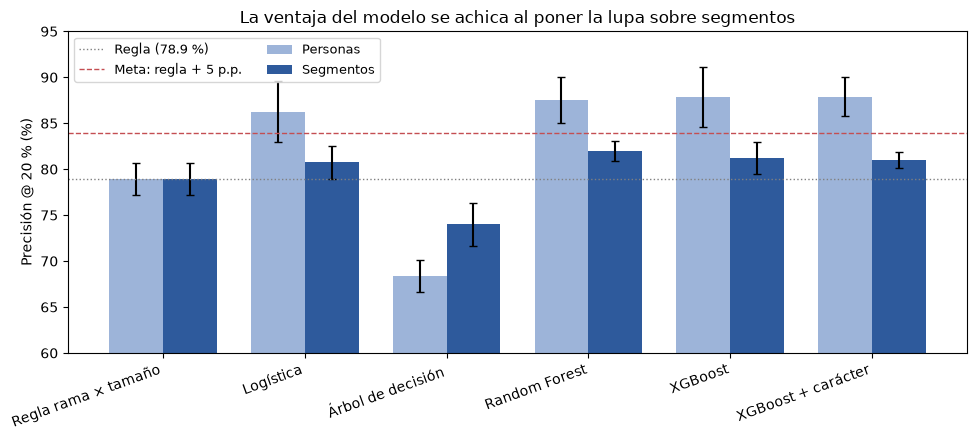

In [17]:
# =============================================================================
# 9.3) Figura 2, precisión a nivel personas y a nivel segmentos
# =============================================================================
modelos_fig = ['Regla rama × tamaño'] + ORDEN_SIMPLICIDAD
resumen = (resultados_cv[resultados_cv['población'] == 'Todos']
           .groupby(['modelo', 'nivel'])['precision@20'].agg(['mean', 'std']) * 100)
fig, eje = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(modelos_fig))
ancho = 0.38
for j, (nivel, color) in enumerate([('Personas', '#9DB4D9'), ('Segmentos', '#2E5A9C')]):
    r = resumen.xs(nivel, level='nivel').reindex(modelos_fig)
    eje.bar(x + (j - 0.5) * ancho, r['mean'], ancho, yerr=r['std'], capsize=3, color=color, label=nivel)
valor_regla = resumen.loc[('Regla rama × tamaño', 'Personas'), 'mean']
eje.axhline(valor_regla, color='gray', ls=':', lw=1, label=f'Regla ({valor_regla:.1f} %)')
eje.axhline(valor_regla + 5, color='#C44E52', ls='--', lw=1, label='Meta: regla + 5 p.p.')
eje.set_xticks(x, modelos_fig, rotation=20, ha='right')
eje.set_ylim(60, 95)
eje.set_ylabel('Precisión @ 20 % (%)')
eje.set_title('La ventaja del modelo se achica al poner la lupa sobre segmentos')
eje.legend(loc='upper left', ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig2_personas_vs_segmentos.png', dpi=150)
plt.show()

Variación del score de Random Forest: 80% entre segmentos y 20% dentro de los segmentos.


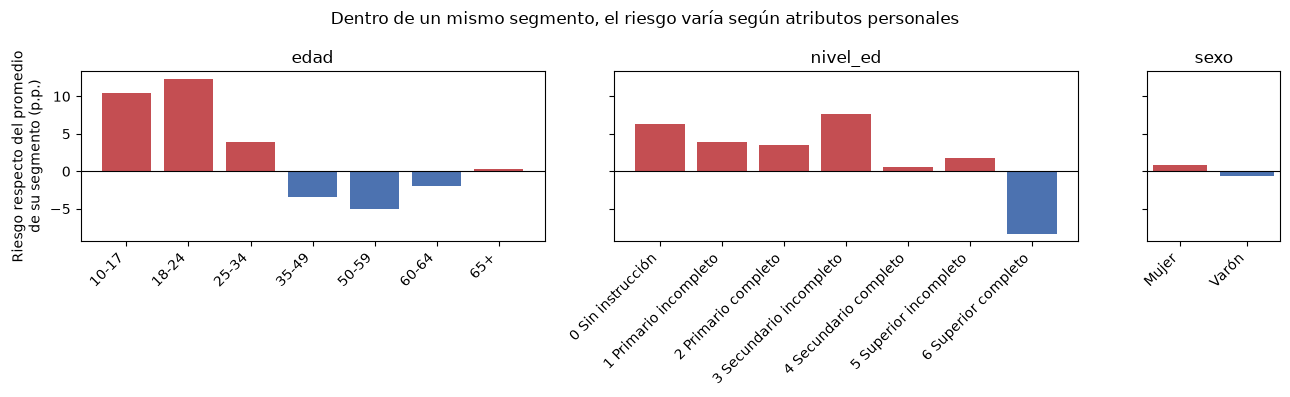

In [18]:
# =============================================================================
# 9.4) Figura 3, variación del riesgo dentro de los segmentos
# =============================================================================
s_oof = oof[ELEGIDO]
s_oof_seg = score_segmento(s_oof, w_dev, dev['segmento'])
promedio = np.average(s_oof, weights=w_dev)
var_total = np.average((s_oof - promedio) ** 2, weights=w_dev)
var_entre = np.average((s_oof_seg - promedio) ** 2, weights=w_dev)
print(f'Variación del score de {ELEGIDO}: {var_entre / var_total:.0%} entre segmentos y '
      f'{1 - var_entre / var_total:.0%} dentro de los segmentos.')

dentro = dev[['edad', 'nivel_ed', 'sexo']].assign(w=w_dev, wd=(s_oof - s_oof_seg) * 100 * w_dev)
fig, ejes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, gridspec_kw={'width_ratios': [7, 7, 2]})
for eje, col in zip(ejes, ['edad', 'nivel_ed', 'sexo']):
    g = dentro.groupby(col)['wd'].sum() / dentro.groupby(col)['w'].sum()
    eje.bar(g.index, g.values, color=np.where(g.values > 0, '#C44E52', '#4C72B0'))
    eje.axhline(0, color='black', lw=0.8)
    eje.set_title(col)
    plt.setp(eje.get_xticklabels(), rotation=45, ha='right')
ejes[0].set_ylabel('Riesgo respecto del promedio\nde su segmento (p.p.)')
fig.suptitle('Dentro de un mismo segmento, el riesgo varía según atributos personales')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig3_riesgo_dentro_de_segmentos.png', dpi=150)
plt.show()

In [19]:
# =============================================================================
# 9.5) Sensibilidad del árbol a la profundidad (no interviene en la selección)
# =============================================================================
filas = []
for profundidad, hoja in [(6, 50), (8, 30), (12, 20), (None, 30)]:
    arbol = ajustar_y_puntuar(DecisionTreeClassifier(max_depth=profundidad, min_samples_leaf=hoja,
                                                     random_state=SEED))
    r, o = validacion_cruzada({'árbol': arbol})
    medias = r[r['población'] == 'Todos'].groupby('nivel')['precision@20'].mean() * 100
    filas.append({'profundidad': profundidad or 'sin límite', 'hoja mínima': hoja,
                  'scores distintos (5 folds)': len(np.unique(o['árbol'])), **medias.round(1).to_dict()})
pd.DataFrame(filas)

,profundidad,hoja mínima,scores distintos (5 folds),Personas,Segmentos
0,6,50,171,68.4,74.0
1,8,30,288,72.0,76.5
2,12,20,403,79.0,80.9
3,sin límite,30,681,83.3,80.4


## 10) Evaluación final en test

Se ejecuta una sola vez con la selección ya cerrada. El elegido y la regla se reentrenan con todo el desarrollo y se evalúan sobre el 20 % reservado, los demás candidatos se muestran solo como referencia.

In [20]:
# =============================================================================
# 10) Métricas en test
# =============================================================================
TODOS_LOS_MODELOS = {**MODELOS, **MODELOS_NO_LINEALES}
y_test, w_test = test['informal'].values, test['PONDERA'].values.astype(float)
en_test = ['Azar', 'Regla rama × tamaño', ELEGIDO] + [n for n in ORDEN_SIMPLICIDAD if n != ELEGIDO]
s_test = {n: TODOS_LOS_MODELOS[n](dev, y_dev, w_dev, test) for n in en_test}


def rol(n):
    if n == ELEGIDO:
        return 'elegido'
    return 'benchmark' if n in MODELOS and n != 'Logística' else 'referencia'


resultados_test = pd.DataFrame([{'modelo': n, 'rol': rol(n), **f}
                                for n, s in s_test.items() for f in evaluar(test, s)])
resultados_test.to_csv(RESULTS_DIR / 'test_resultados.csv', index=False)
tabla_test = (resultados_test.pivot_table(index=['modelo', 'rol'], columns=['población', 'nivel'],
                                          values='precision@20', sort=False) * 100).round(1)
tabla_test

población                         Todos           Asal. privados          
nivel                          Personas Segmentos       Personas Segmentos
modelo              rol                                                   
Azar                benchmark      42.8      42.8           40.6      40.6
Regla rama × tamaño benchmark      75.3      75.3           74.3      74.3
Random Forest       elegido        85.7      77.8           86.6      74.7
Logística           referencia     85.6      73.9           87.1      74.3
Árbol de decisión   referencia     67.2      68.2           61.2      64.3
XGBoost             referencia     87.9      74.2           88.0      75.2
XGBoost + carácter  referencia     88.6      75.1           90.8      77.0

In [21]:
# =============================================================================
# 10.1) Métricas complementarias y ventaja del elegido sobre la regla
# =============================================================================
s_elegido_seg = score_segmento(s_test[ELEGIDO], w_test, test['segmento'])
base_test = np.average(y_test, weights=w_test)
alc = test['alcanzable'].values
print(pd.DataFrame({n: metricas(y_test, s_test[n], w_test) for n in en_test[1:]}).T.round(3).to_string())

vistas = {
    'Todos | segmentos (criterio)': (np.ones(len(test), bool), s_elegido_seg),
    'Todos | personas': (np.ones(len(test), bool), s_test[ELEGIDO]),
    'Asal. privados | segmentos': (alc, s_elegido_seg),
}
filas, difs = [], {}
for vista, (m, s_modelo) in vistas.items():
    b = bootstrap_viviendas(y_test[m], {'modelo': s_modelo[m], 'regla': s_test['Regla rama × tamaño'][m]},
                            w_test[m], test['CODUSU'].values[m])
    dif = (b['modelo'] - b['regla']) * 100
    difs[vista] = dif
    filas.append({'vista': vista,
                  'modelo': top_k(y_test[m], s_modelo[m], w_test[m])[0] * 100,
                  'regla': top_k(y_test[m], s_test['Regla rama × tamaño'][m], w_test[m])[0] * 100,
                  'ventaja (p.p.)': dif.mean(), 'IC 2,5 %': np.percentile(dif, 2.5),
                  'IC 97,5 %': np.percentile(dif, 97.5), 'P(ventaja ≥ 5)': (dif >= 5).mean()})
ventaja_test = pd.DataFrame(filas).round(2)
ventaja_test.to_csv(RESULTS_DIR / 'test_ventaja_sobre_regla.csv', index=False)
ventaja_test

                     precision@20  recall@20  f1@20  lift@20    AUC  PR-AUC
Regla rama × tamaño         0.753      0.352  0.480    1.761  0.807   0.714
Random Forest               0.857      0.401  0.546    2.003  0.862   0.812
Logística                   0.856      0.400  0.546    2.002  0.862   0.817
Árbol de decisión           0.672      0.314  0.428    1.570  0.790   0.656
XGBoost                     0.879      0.411  0.560    2.055  0.870   0.829
XGBoost + carácter          0.886      0.414  0.564    2.070  0.876   0.837


,vista,modelo,regla,ventaja (p.p.),"IC 2,5 %","IC 97,5 %",P(ventaja ≥ 5)
0,Todos | segmentos (criterio),77.83,75.33,2.39,-1.53,5.98,0.09
1,Todos | personas,85.68,75.33,10.66,6.22,15.65,0.99
2,Asal. privados | segmentos,74.73,74.33,0.13,-6.30,5.83,0.06


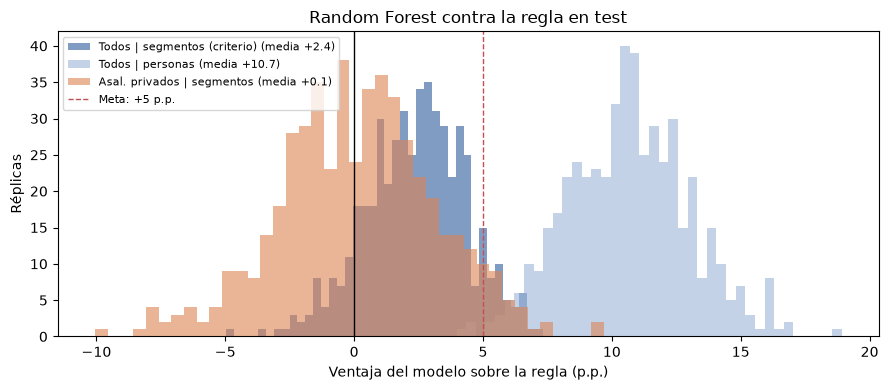

In [22]:
# =============================================================================
# 10.2) Figura 4, distribución bootstrap de la ventaja en test
# =============================================================================
fig, eje = plt.subplots(figsize=(9, 4))
colores = ['#2E5A9C', '#9DB4D9', '#DD8452']
for (vista, dif), color in zip(difs.items(), colores):
    eje.hist(dif, bins=40, alpha=0.6, color=color, label=f'{vista} (media {dif.mean():+.1f})')
eje.axvline(0, color='black', lw=1)
eje.axvline(5, color='#C44E52', ls='--', lw=1, label='Meta: +5 p.p.')
eje.set_xlabel('Ventaja del modelo sobre la regla (p.p.)')
eje.set_ylabel('Réplicas')
eje.set_title(f'{ELEGIDO} contra la regla en test')
eje.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig4_bootstrap_ventaja_test.png', dpi=150)
plt.show()

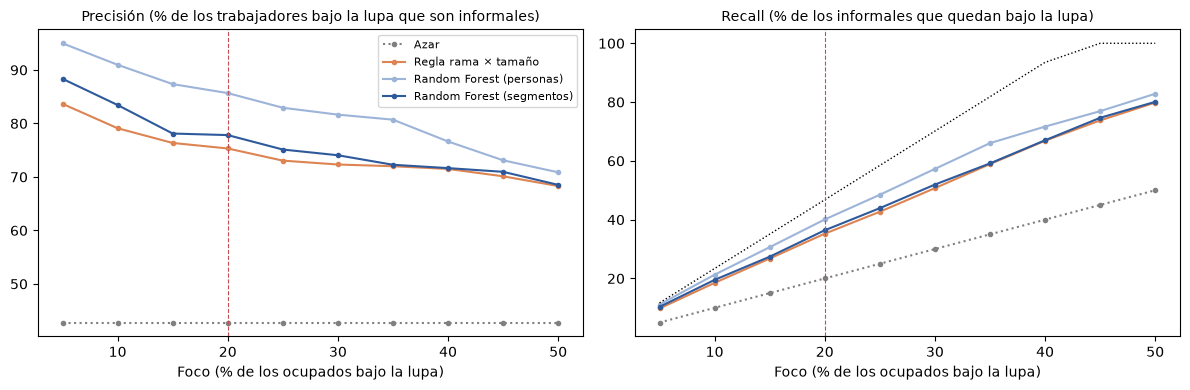

Lupa sobre el 20% de los ocupados = 2.7 millones
                       azar: 43 informales cada 100, ~1.15 millones (20% de los informales)
                      regla: 75 informales cada 100, ~2.03 millones (35% de los informales)
  Random Forest (segmentos): 78 informales cada 100, ~2.09 millones (36% de los informales)


In [23]:
# =============================================================================
# 10.3) Figura 5, precisión y recall según el tamaño del foco
# =============================================================================
focos = np.arange(0.05, 0.51, 0.05)
curvas = {'Azar': np.zeros(len(test)), 'Regla rama × tamaño': s_test['Regla rama × tamaño'],
          f'{ELEGIDO} (personas)': s_test[ELEGIDO], f'{ELEGIDO} (segmentos)': s_elegido_seg}
estilos = {'Azar': ('gray', ':'), 'Regla rama × tamaño': ('#DD8452', '-'),
           f'{ELEGIDO} (personas)': ('#9DB4D9', '-'), f'{ELEGIDO} (segmentos)': ('#2E5A9C', '-')}
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for nombre, score in curvas.items():
    valores = np.array([top_k(y_test, score, w_test, k=c) for c in focos]) * 100
    color, linea = estilos[nombre]
    ejes[0].plot(focos * 100, valores[:, 0], color=color, ls=linea, marker='o', ms=3, label=nombre)
    ejes[1].plot(focos * 100, valores[:, 1], color=color, ls=linea, marker='o', ms=3, label=nombre)
ejes[1].plot(focos * 100, np.minimum(focos / base_test, 1) * 100, color='black', ls=':', lw=1, label='Techo')
for eje, titulo in zip(ejes, ['Precisión (% de los trabajadores bajo la lupa que son informales)',
                              'Recall (% de los informales que quedan bajo la lupa)']):
    eje.axvline(K * 100, color='#C44E52', ls='--', lw=0.8)
    eje.set_xlabel('Foco (% de los ocupados bajo la lupa)')
    eje.set_title(titulo, fontsize=10)
ejes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig5_curva_por_foco_test.png', dpi=150)
plt.show()

precision_seg, recall_seg = top_k(y_test, s_elegido_seg, w_test)
precision_regla_t, recall_regla_t = top_k(y_test, s_test['Regla rama × tamaño'], w_test)
print(f'Lupa sobre el {K:.0%} de los ocupados = {K * poblacion / 1e6:.1f} millones')
for quien, a, c in [('azar', base_test, K), ('regla', precision_regla_t, recall_regla_t),
                    (f'{ELEGIDO} (segmentos)', precision_seg, recall_seg)]:
    print(f'  {quien:>25}: {100 * a:.0f} informales cada 100, ~{K * poblacion * a / 1e6:.2f} millones '
          f'({c:.0%} de los informales)')

## 11) Ablaciones (H1 y H2)

Se reentrena el modelo elegido sacando un bloque de variables por vez, con los mismos 5 folds, y se mide la caída de la precisión respecto del modelo completo.

In [24]:
# =============================================================================
# 11) Ablaciones en validación cruzada
# =============================================================================
ESTIMADORES = {'Árbol de decisión': ARBOL, 'Random Forest': RANDOM_FOREST, 'XGBoost': XGBOOST}
ESTIMADOR = ESTIMADORES[ELEGIDO]

BLOQUES = {
    'Sin rama ni tamaño (H1)': ['rama', 'tamano'],
    'Sin edad, sexo ni educación (H2)': ['edad', 'sexo', 'nivel_ed'],
    'Sin sexo': ['sexo'],
    'Sin calificación': ['calificacion'],
    'Sin categoría ni ámbito': ['cat_ocup', 'ambito'],
    'Sin región': ['region'],
}
variantes = {nombre: ajustar_y_puntuar(ESTIMADOR, [f for f in FEATURES if f not in quitar])
             for nombre, quitar in BLOQUES.items()}
variantes['Solo rama y tamaño'] = ajustar_y_puntuar(ESTIMADOR, ['rama', 'tamano'])
resultados_abl, oof_abl = validacion_cruzada(variantes)

clave = ['fold', 'población', 'nivel']
completo = resultados_cv.loc[resultados_cv['modelo'] == ELEGIDO, clave + ['precision@20']]
regla_cv = resultados_cv.loc[resultados_cv['modelo'] == 'Regla rama × tamaño', clave + ['precision@20']]
comparadas = pd.concat([resultados_abl, regla_cv.assign(modelo='Regla rama × tamaño (referencia)')])
caidas = comparadas.merge(completo, on=clave, suffixes=('', '_completo'))
caidas['caída (p.p.)'] = (caidas['precision@20_completo'] - caidas['precision@20']) * 100
caidas = caidas[caidas['población'] == 'Todos']

resumen_abl = caidas.pivot_table(index='modelo', columns='nivel', values='caída (p.p.)',
                                 aggfunc=['mean', 'std'], sort=False)
tabla_abl = resumen_abl['mean'].round(1).astype(str) + ' ± ' + resumen_abl['std'].round(1).astype(str)
tabla_abl['PR-AUC (personas)'] = [round(average_precision_score(y_dev, oof_abl[n], sample_weight=w_dev), 3)
                                  if n in oof_abl else None for n in tabla_abl.index]
tabla_abl.columns.name = None
tabla_abl.to_csv(RESULTS_DIR / 'ablaciones_cv.csv')
print(f'PR-AUC de {ELEGIDO} completo: {average_precision_score(y_dev, oof[ELEGIDO], sample_weight=w_dev):.3f}')
tabla_abl

PR-AUC de Random Forest completo: 0.820


,Personas,Segmentos,PR-AUC (personas)
modelo,,,
Sin rama ni tamaño (H1),5.7 ± 0.7,6.6 ± 3.6,0.755
"Sin edad, sexo ni educación (H2)",2.9 ± 1.7,0.5 ± 1.1,0.794
Sin sexo,0.8 ± 0.8,-0.2 ± 0.5,0.817
Sin calificación,0.5 ± 1.4,0.7 ± 1.1,0.815
Sin categoría ni ámbito,-0.0 ± 0.5,-0.1 ± 0.6,0.817
Sin región,0.2 ± 0.6,1.7 ± 1.5,0.816
Solo rama y tamaño,6.7 ± 2.1,1.6 ± 1.1,0.753
Regla rama × tamaño (referencia),8.6 ± 1.0,3.1 ± 1.3,NaN


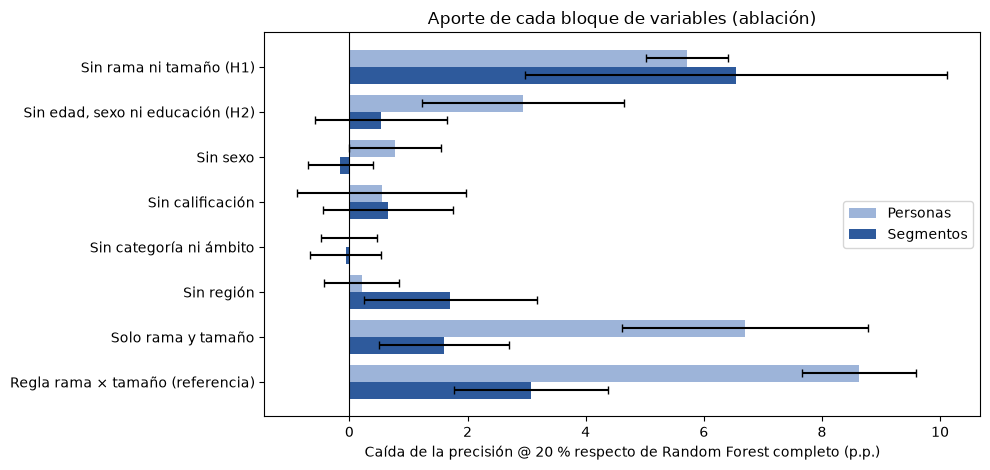

In [25]:
# =============================================================================
# 11.1) Figura 6, caída de la precisión al sacar cada bloque
# =============================================================================
orden = list(BLOQUES) + ['Solo rama y tamaño', 'Regla rama × tamaño (referencia)']
fig, eje = plt.subplots(figsize=(10, 4.8))
y_pos = np.arange(len(orden))
alto = 0.38
for j, (nivel, color) in enumerate([('Personas', '#9DB4D9'), ('Segmentos', '#2E5A9C')]):
    media = resumen_abl[('mean', nivel)].reindex(orden)
    desvio = resumen_abl[('std', nivel)].reindex(orden)
    eje.barh(y_pos + (j - 0.5) * alto, media, alto, xerr=desvio, capsize=3, color=color, label=nivel)
eje.axvline(0, color='black', lw=0.8)
eje.set_yticks(y_pos, orden)
eje.invert_yaxis()
eje.set_xlabel(f'Caída de la precisión @ 20 % respecto de {ELEGIDO} completo (p.p.)')
eje.set_title('Aporte de cada bloque de variables (ablación)')
eje.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig6_ablaciones.png', dpi=150)
plt.show()

## 12) Alcance de las herramientas (H3) y composición de lo que queda bajo la lupa

Se clasifica a cada ocupado según qué herramienta del Estado puede llevarlo a la formalidad (supuestos validados contra la Ley 27.802 y su reglamentación) y se mira cómo se compone el 20 % del empleo que queda bajo la lupa con cada método.

In [26]:
# =============================================================================
# 12) Grupos según la herramienta que puede alcanzarlos
# =============================================================================
GRUPOS_ALCANCE = [
    'Asal. privados de más de 5 (o s/d): inspección e incentivos',
    'Asal. privados de hasta 5: inspección con acompañamiento',
    'Casas particulares: medidas específicas',
    'Asal. sector público u otro: fuera del análisis',
    'Cuenta propia: otras medidas (sin empleador)',
    'Patrones y familiares: otras medidas',
]


def grupo_alcance(df):
    condiciones = [
        df['alcanzable'] & (df['tamano_regla'] != 'Hasta 5'),
        df['alcanzable'] & (df['tamano_regla'] == 'Hasta 5'),
        df['tamano'] == 'Casas particulares',
        df['cat_ocup'] == 'Asalariado',
        df['cat_ocup'] == 'Cuenta propia',
        df['cat_ocup'].isin(['Patrón', 'Trabajador familiar']),
    ]
    return np.select(condiciones, GRUPOS_ALCANCE, 'Sin clasificar')


d['alcance'] = grupo_alcance(d)
assert (d['alcance'] != 'Sin clasificar').all()
g = d.groupby('alcance')
tabla_h3 = pd.DataFrame({
    '% de ocupados': g['PONDERA'].sum() / poblacion * 100,
    'tasa de informalidad (%)': g['wy'].sum() / g['PONDERA'].sum() * 100,
    '% de los informales': g['wy'].sum() / d['wy'].sum() * 100,
}).reindex(GRUPOS_ALCANCE).round(1)
tabla_h3.to_csv(RESULTS_DIR / 'h3_alcance_instrumentos.csv')
tabla_h3

,% de ocupados,tasa de informalidad (%),% de los informales
alcance,,,
Asal. privados de más de 5 (o s/d): inspección e incentivos,35.4,29.3,23.5
Asal. privados de hasta 5: inspección con acompañamiento,13.3,72.8,21.9
Casas particulares: medidas específicas,6.6,77.5,11.6
Asal. sector público u otro: fuera del análisis,16.5,12.1,4.5
Cuenta propia: otras medidas (sin empleador),24.2,65.3,35.7
Patrones y familiares: otras medidas,4.0,30.7,2.8


In [27]:
# =============================================================================
# 12.1) Composición del 20 % bajo la lupa (predicciones fuera de fold)
# =============================================================================
priorizaciones = {
    'Regla rama × tamaño': oof['Regla rama × tamaño'],
    f'{ELEGIDO} (segmentos)': score_segmento(oof[ELEGIDO], w_dev, dev['segmento']),
    f'{ELEGIDO} (personas)': oof[ELEGIDO],
}
alcance_dev = grupo_alcance(dev)
alcanzado = dev['alcanzable'].values
composicion, resumen_alcance = {}, {}
for nombre, score in priorizaciones.items():
    pw = fraccion_seleccionada(score, w_dev) * w_dev
    assert np.isclose((pw * y_dev).sum() / pw.sum(), top_k(y_dev, score, w_dev)[0])
    composicion[nombre] = pd.Series(pw).groupby(alcance_dev).sum() / pw.sum() * 100
    resumen_alcance[nombre] = {
        'informales cada 100 bajo la lupa': (pw * y_dev).sum() / pw.sum() * 100,
        'informales con empleador privado cada 100': (pw * y_dev * alcanzado).sum() / pw.sum() * 100,
    }
composicion['Todos los ocupados'] = pd.Series(w_dev).groupby(alcance_dev).sum() / w_dev.sum() * 100
composicion = pd.DataFrame(composicion).reindex(GRUPOS_ALCANCE).round(1)
resumen_alcance = pd.DataFrame(resumen_alcance).T.round(1)
composicion.to_csv(RESULTS_DIR / 'composicion_bajo_la_lupa.csv')
resumen_alcance.to_csv(RESULTS_DIR / 'bajo_la_lupa_con_empleador.csv')
display(resumen_alcance)
composicion

,informales cada 100 bajo la lupa,informales con empleador privado cada 100
Regla rama × tamaño,78.5,20.2
Random Forest (segmentos),80.8,18.9
Random Forest (personas),87.3,21.7


,Regla rama × tamaño,Random Forest (segmentos),Random Forest (personas),Todos los ocupados
Asal. privados de más de 5 (o s/d): inspección e incentivos,0.2,0.0,0.7,35.4
Asal. privados de hasta 5: inspección con acompañamiento,24.6,22.0,23.6,13.2
Casas particulares: medidas específicas,32.4,32.4,23.1,6.5
Asal. sector público u otro: fuera del análisis,0.1,0.1,0.0,16.7
Cuenta propia: otras medidas (sin empleador),38.3,41.6,51.7,24.4
Patrones y familiares: otras medidas,4.4,3.8,0.9,4.0


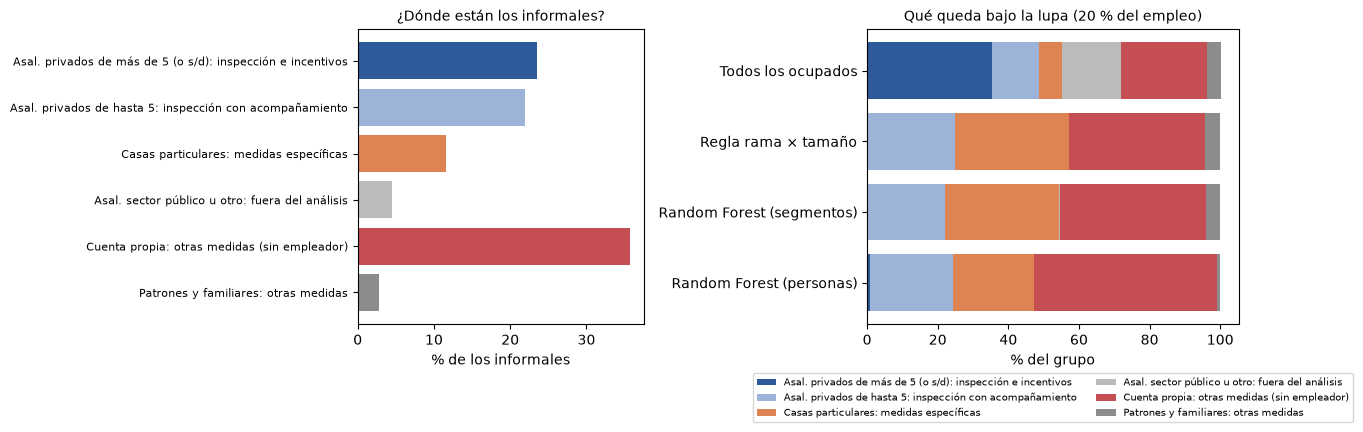

In [28]:
# =============================================================================
# 12.2) Figura 7, dónde están los informales y qué queda bajo la lupa
# =============================================================================
colores_alcance = ['#2E5A9C', '#9DB4D9', '#DD8452', '#BBBBBB', '#C44E52', '#8C8C8C']
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1, 1.3]})
h3 = tabla_h3['% de los informales']
ejes[0].barh(range(len(h3)), h3.values, color=colores_alcance)
ejes[0].set_yticks(range(len(h3)), h3.index, fontsize=8)
ejes[0].invert_yaxis()
ejes[0].set_xlabel('% de los informales')
ejes[0].set_title('¿Dónde están los informales?', fontsize=10)

columnas = ['Todos los ocupados', 'Regla rama × tamaño', f'{ELEGIDO} (segmentos)', f'{ELEGIDO} (personas)']
izquierda = np.zeros(len(columnas))
for grupo, color in zip(GRUPOS_ALCANCE, colores_alcance):
    valores = composicion.loc[grupo, columnas].values
    ejes[1].barh(columnas, valores, left=izquierda, color=color, label=grupo)
    izquierda += valores
ejes[1].invert_yaxis()
ejes[1].set_xlabel('% del grupo')
ejes[1].set_title('Qué queda bajo la lupa (20 % del empleo)', fontsize=10)
ejes[1].legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig7_alcance_instrumentos.png', dpi=150, bbox_inches='tight')
plt.show()

## 13) Deciles e impacto de la lupa

Deciles de riesgo en test y comparación de escenarios que ponen la lupa sobre la misma cantidad de trabajadores (2,7 millones), buscando entre todos los ocupados o solo entre los asalariados privados.

In [29]:
# =============================================================================
# 13) Deciles en test
# =============================================================================
def tabla_deciles(y, score, w):
    filas, previo = [], np.zeros(len(y))
    for j in range(1, 11):
        acumulado = fraccion_seleccionada(score, w, k=j / 10)
        pw = (acumulado - previo) * w
        previo = acumulado
        filas.append({'decil': j, 'w': pw.sum(), 'wy': (pw * y).sum()})
    t = pd.DataFrame(filas).set_index('decil')
    base = np.average(y, weights=w)
    return pd.DataFrame({
        'tasa de informalidad (%)': t['wy'] / t['w'] * 100,
        'lift': t['wy'] / t['w'] / base,
        'recall acumulado (%)': t['wy'].cumsum() / t['wy'].sum() * 100,
    }).round(2)


deciles = pd.concat({
    'Todos los ocupados': tabla_deciles(y_test, s_elegido_seg, w_test),
    'Asal. privados': tabla_deciles(y_test[alc], s_elegido_seg[alc], w_test[alc]),
}, axis=1)
deciles.to_csv(RESULTS_DIR / 'deciles_test.csv')
deciles

Todos los ocupados                             \
      tasa de informalidad (%)  lift recall acumulado (%)   
decil                                                       
1                        83.45  1.95                19.51   
2                        72.20  1.69                36.39   
3                        66.52  1.56                51.94   
4                        64.43  1.51                67.00   
5                        55.98  1.31                80.09   
6                        30.39  0.71                87.19   
7                        26.19  0.61                93.32   
8                        14.12  0.33                96.62   
9                         9.32  0.22                98.79   
10                        5.16  0.12               100.00   

                Asal. privados                             
      tasa de informalidad (%)  lift recall acumulado (%)  
decil                                                      
1                        74.89  1.85                18.46  
2                        74.57  1.84                36.85  
3                        73.47  1.81                54.96  
4                        48.30  1.19                66.87  
5                        32.41  0.80                74.86  
6                        32.66  0.81                82.91  
7                        32.50  0.80                90.93  
8                        13.38  0.33                94.23  
9                        12.23  0.30                97.24  
10                       11.19  0.28               100.00

In [30]:
# =============================================================================
# 13.1) Escenarios de impacto (misma lupa, distinto lugar)
# =============================================================================
escala = poblacion / w_test.sum()
todos_t = np.ones(len(test), bool)
k_igual = min(1.0, K * w_test.sum() / w_test[alc].sum())


def escenario(nombre, score, mascara, k):
    f = np.zeros(len(test))
    f[mascara] = fraccion_seleccionada(score[mascara], w_test[mascara], k)
    pw = f * w_test
    bajo_lupa = pw.sum() * escala
    informales = (pw * y_test).sum() * escala
    con_empleador = (pw * y_test * alc).sum() * escala
    return {'escenario': nombre,
            'trabajadores bajo la lupa (millones)': bajo_lupa / 1e6,
            'informales cada 100': informales / bajo_lupa * 100,
            'informales con empleador privado cada 100': con_empleador / bajo_lupa * 100,
            'trabajadores bajo la lupa por informal con empleador privado': bajo_lupa / con_empleador,
            'informales con empleador privado bajo la lupa (miles)': con_empleador / 1e3}


regla_t = s_test['Regla rama × tamaño']
impacto = pd.DataFrame([
    escenario('Azar, todos los ocupados', np.zeros(len(test)), todos_t, K),
    escenario('Regla, todos los ocupados', regla_t, todos_t, K),
    escenario(f'{ELEGIDO} (segmentos), todos los ocupados', s_elegido_seg, todos_t, K),
    escenario('Azar, asal. privados', np.zeros(len(test)), alc, k_igual),
    escenario('Regla, asal. privados', regla_t, alc, k_igual),
    escenario(f'{ELEGIDO} (segmentos), asal. privados', s_elegido_seg, alc, k_igual),
]).set_index('escenario').round(1)
impacto.to_csv(RESULTS_DIR / 'impacto_escenarios_test.csv')
print(f'Lupa dentro de los asalariados privados: {k_igual:.0%} de esa población')
impacto

Lupa dentro de los asalariados privados: 40% de esa población


,trabajadores bajo la lupa (millones),informales cada 100,informales con empleador privado cada 100,trabajadores bajo la lupa por informal con empleador privado,informales con empleador privado bajo la lupa (miles)
escenario,,,,,
"Azar, todos los ocupados",2.7,42.8,20.1,5.0,541.6
"Regla, todos los ocupados",2.7,75.3,20.5,4.9,551.4
"Random Forest (segmentos), todos los ocupados",2.7,77.8,16.1,6.2,433.3
"Azar, asal. privados",2.7,40.6,40.6,2.5,1091.7
"Regla, asal. privados",2.7,66.2,66.2,1.5,1782.7
"Random Forest (segmentos), asal. privados",2.7,67.5,67.5,1.5,1817.8


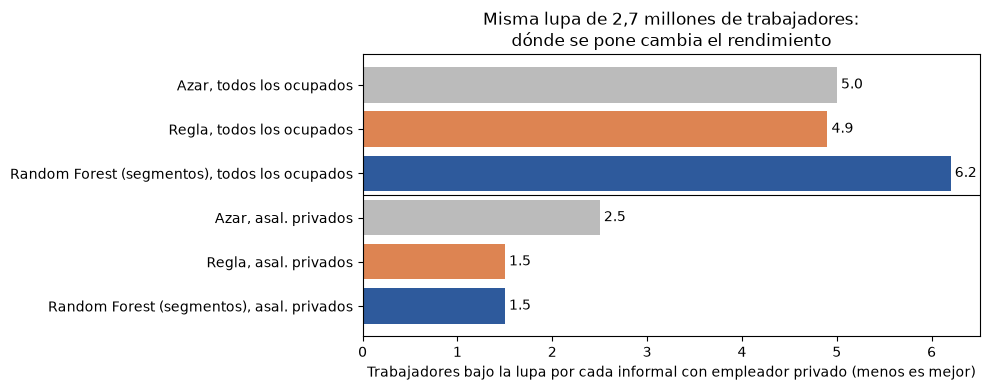

In [31]:
# =============================================================================
# 13.2) Figura 8, trabajadores bajo la lupa por cada informal con empleador privado
# =============================================================================
valores = impacto['trabajadores bajo la lupa por informal con empleador privado']
colores = ['#BBBBBB', '#DD8452', '#2E5A9C'] * 2
fig, eje = plt.subplots(figsize=(10, 4))
barras = eje.barh(valores.index, valores.values, color=colores)
eje.bar_label(barras, fmt='%.1f', padding=3)
eje.invert_yaxis()
eje.axhline(2.5, color='black', lw=0.8)
eje.set_xlabel('Trabajadores bajo la lupa por cada informal con empleador privado (menos es mejor)')
eje.set_title('Misma lupa de 2,7 millones de trabajadores:\ndónde se pone cambia el rendimiento')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig8_impacto_lupa.png', dpi=150)
plt.show()

## 14) Sectores donde poner la lupa

Segmentos rama × tamaño de asalariados privados con al menos 30 casos, calculados sobre toda la muestra ponderada. Los segmentos con menos de 100 casos se marcan con confiabilidad baja.

In [32]:
# =============================================================================
# 14) Ranking de segmentos
# =============================================================================
def tabla_segmentos(df, claves, min_casos=30):
    g = df.groupby(claves)
    t = pd.DataFrame({
        'casos': g.size(),
        'ocupados (miles)': g['PONDERA'].sum() / 1e3,
        'informales (miles)': g['wy'].sum() / 1e3,
    })
    t['tasa de informalidad (%)'] = t['informales (miles)'] / t['ocupados (miles)'] * 100
    t = t[t['casos'] >= min_casos].sort_values('tasa de informalidad (%)', ascending=False)
    t['% de los informales con empleador privado (acum.)'] = t['informales (miles)'].cumsum() / (df['wy'].sum() / 1e3) * 100
    t['confiabilidad'] = np.where(t['casos'] >= 100, 'normal', 'baja')
    return t.round(1)


asal_privados = d[d['alcanzable']]
segmentos = tabla_segmentos(asal_privados, ['rama', 'tamano_regla'])
segmentos.to_csv(RESULTS_DIR / 'sectores_bajo_la_lupa.csv')
tabla_segmentos(asal_privados, ['rama', 'tamano_regla', 'region']).to_csv(
    RESULTS_DIR / 'sectores_bajo_la_lupa_por_region.csv')
print(f'Segmentos con al menos 30 casos: {len(segmentos)}; informales con empleador privado: '
      f'{asal_privados["wy"].sum() / 1e6:.2f} millones')
segmentos.head(15)

Segmentos con al menos 30 casos: 50; informales con empleador privado: 2.71 millones


,,casos,ocupados (miles),informales (miles),tasa de informalidad (%),% de los informales con empleador privado (acum.),confiabilidad
rama,tamano_regla,,,,,,
F Construcción,Hasta 5,513,306.3,287.9,94.0,10.6,normal
R Arte y recreación,Hasta 5,51,30.8,26.9,87.2,11.6,baja
I Alojamiento y gastronomía,Hasta 5,232,182.8,142.6,78.0,16.9,normal
H Transporte,Hasta 5,105,84.3,65.4,77.6,19.3,normal
C Industria,Hasta 5,216,203.0,151.6,74.7,24.9,normal
G Comercio,Hasta 5,917,581.7,413.6,71.1,40.2,normal
R Arte y recreación,6 a 40,72,48.6,33.6,69.2,41.5,baja
A Agro y pesca,Hasta 5,35,11.7,7.9,67.8,41.8,baja
M Profesionales,Hasta 5,80,74.1,49.0,66.1,43.6,baja


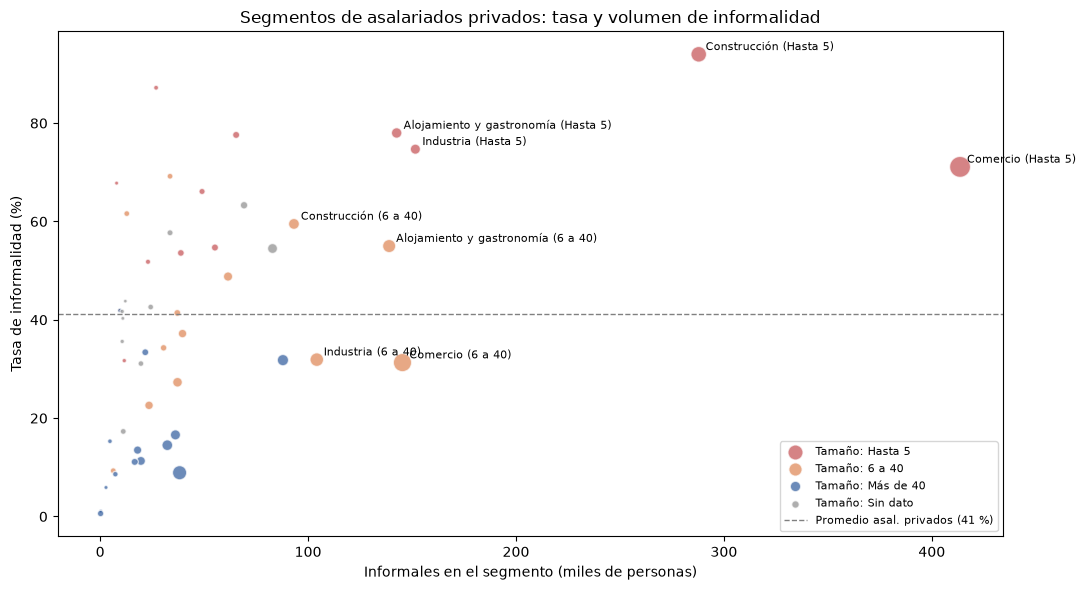

In [33]:
# =============================================================================
# 14.1) Figura 9, mapa de segmentos por tasa y volumen
# =============================================================================
colores_tam = {'Hasta 5': '#C44E52', '6 a 40': '#DD8452', 'Más de 40': '#2E5A9C', 'Sin dato': '#8C8C8C'}
seg = segmentos.reset_index()
fig, eje = plt.subplots(figsize=(11, 6))
for tam, color in colores_tam.items():
    sub = seg[seg['tamano_regla'] == tam]
    eje.scatter(sub['informales (miles)'], sub['tasa de informalidad (%)'], s=sub['casos'] / 4,
                color=color, alpha=0.7, label=f'Tamaño: {tam}', edgecolor='white')
for _, fila in seg.nlargest(8, 'informales (miles)').iterrows():
    rama = fila['rama'].split(' ', 1)[1] if fila['rama'][1:2] == ' ' else fila['rama']
    eje.annotate(f"{rama} ({fila['tamano_regla']})",
                 (fila['informales (miles)'], fila['tasa de informalidad (%)']),
                 fontsize=8, xytext=(5, 3), textcoords='offset points')
tasa_alc = asal_privados['wy'].sum() / asal_privados['PONDERA'].sum() * 100
eje.axhline(tasa_alc, color='gray', ls='--', lw=1, label=f'Promedio asal. privados ({tasa_alc:.0f} %)')
eje.set_xlabel('Informales en el segmento (miles de personas)')
eje.set_ylabel('Tasa de informalidad (%)')
eje.set_title('Segmentos de asalariados privados: tasa y volumen de informalidad')
eje.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig9_mapa_segmentos.png', dpi=150)
plt.show()

## 15) Auditoría por sexo y región

Se audita la herramienta recomendada (la regla dentro de los asalariados privados, con el foco del paso 13) sobre el test, mirando el recall de cada grupo frente al promedio y la calibración del riesgo estimado.

In [34]:
# =============================================================================
# 15) Recall y calibración por grupo
# =============================================================================
f_regla = np.zeros(len(test))
f_regla[alc] = fraccion_seleccionada(regla_t[alc], w_test[alc], k_igual)
auditable = test[alc].assign(
    w=w_test[alc], wy=(w_test * y_test)[alc], sel_wy=(f_regla * w_test * y_test)[alc],
    sel_w=(f_regla * w_test)[alc], regla_w=(regla_t * w_test)[alc],
    modelo_w=(s_test[ELEGIDO] * w_test)[alc])
recall_medio = auditable['sel_wy'].sum() / auditable['wy'].sum() * 100


def auditoria(col):
    g = auditable.groupby(col)
    t = pd.DataFrame({
        'casos': g.size(),
        'tasa real (%)': g['wy'].sum() / g['w'].sum() * 100,
        'riesgo estimado: regla (%)': g['regla_w'].sum() / g['w'].sum() * 100,
        f'riesgo estimado: {ELEGIDO} (%)': g['modelo_w'].sum() / g['w'].sum() * 100,
        '% del grupo bajo la lupa': g['sel_w'].sum() / g['w'].sum() * 100,
        'recall del grupo (%)': g['sel_wy'].sum() / g['wy'].sum() * 100,
    })
    t['recall − promedio (p.p.)'] = t['recall del grupo (%)'] - recall_medio
    t['cumple criterio (≥ −10)'] = t['recall − promedio (p.p.)'] >= -10
    return t.round(1)


tabla_auditoria = pd.concat({'sexo': auditoria('sexo'), 'región': auditoria('region')})
tabla_auditoria.to_csv(RESULTS_DIR / 'auditoria_grupos_test.csv')
print(f'Recall promedio (asal. privados, test): {recall_medio:.1f} %')
tabla_auditoria

Recall promedio (asal. privados, test): 65.8 %


casos  tasa real (%)  riesgo estimado: regla (%)  \
sexo   Mujer        634           41.7                        39.5   
       Varón       1077           39.9                        41.6   
región Cuyo         163           51.0                        40.8   
       GBA          365           38.4                        39.7   
       NEA          143           60.0                        49.6   
       NOA          320           56.1                        46.7   
       Pampeana     539           38.0                        42.1   
       Patagonia    181           25.0                        32.5   

                  riesgo estimado: Random Forest (%)  \
sexo   Mujer                                    42.7   
       Varón                                    41.7   
región Cuyo                                     47.7   
       GBA                                      41.2   
       NEA                                      53.3   
       NOA                                      50.5   
       Pampeana                                 40.5   
       Patagonia                                29.6   

                  % del grupo bajo la lupa  recall del grupo (%)  \
sexo   Mujer                          38.4                  61.7   
       Varón                          41.5                  68.4   
región Cuyo                           36.9                  59.5   
       GBA                            38.4                  64.1   
       NEA                            62.5                  74.7   
       NOA                            50.8                  77.4   
       Pampeana                       41.3                  65.5   
       Patagonia                      29.5                  61.5   

                  recall − promedio (p.p.)  cumple criterio (≥ −10)  
sexo   Mujer                          -4.1                     True  
       Varón                           2.6                     True  
región Cuyo                           -6.3                     True  
       GBA                            -1.7                     True  
       NEA                             8.8                     True  
       NOA                            11.6                     True  
       Pampeana                       -0.3                     True  
       Patagonia                      -4.3                     True

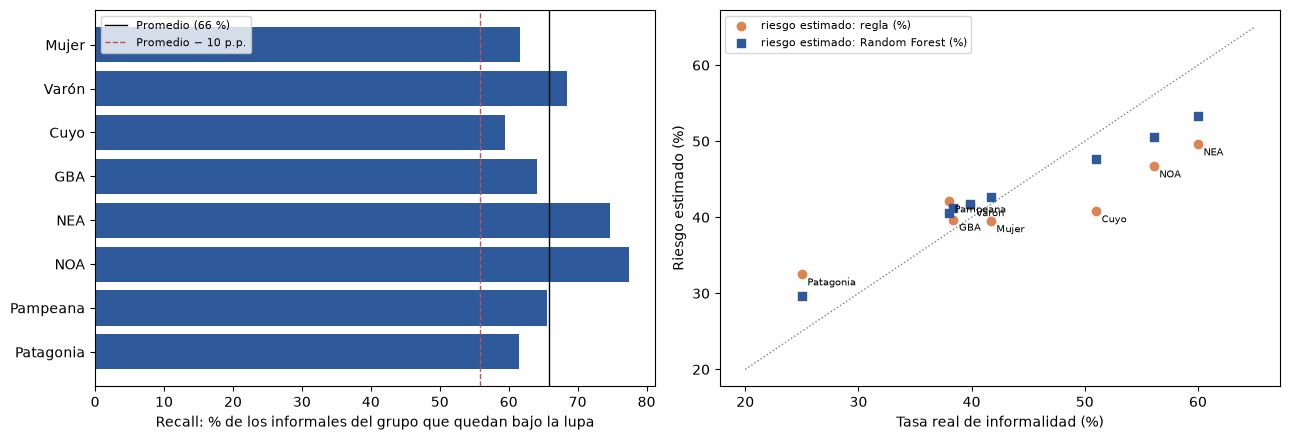

In [35]:
# =============================================================================
# 15.1) Figura 10, recall por grupo y calibración
# =============================================================================
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
t = tabla_auditoria.reset_index(level=0, names='atributo')
ejes[0].barh(t.index, t['recall del grupo (%)'],
             color=np.where(t['cumple criterio (≥ −10)'], '#2E5A9C', '#C44E52'))
ejes[0].axvline(recall_medio, color='black', lw=1, label=f'Promedio ({recall_medio:.0f} %)')
ejes[0].axvline(recall_medio - 10, color='#C44E52', ls='--', lw=1, label='Promedio − 10 p.p.')
ejes[0].invert_yaxis()
ejes[0].set_xlabel('Recall: % de los informales del grupo que quedan bajo la lupa')
ejes[0].legend(fontsize=8)

for columna, marca, color in [('riesgo estimado: regla (%)', 'o', '#DD8452'),
                              (f'riesgo estimado: {ELEGIDO} (%)', 's', '#2E5A9C')]:
    ejes[1].scatter(t['tasa real (%)'], t[columna], marker=marca, color=color, label=columna)
for nombre, fila in t.iterrows():
    ejes[1].annotate(nombre, (fila['tasa real (%)'], fila['riesgo estimado: regla (%)']),
                     fontsize=7, xytext=(4, -8), textcoords='offset points')
limites = [t['tasa real (%)'].min() - 5, t['tasa real (%)'].max() + 5]
ejes[1].plot(limites, limites, color='gray', ls=':', lw=1)
ejes[1].set_xlabel('Tasa real de informalidad (%)')
ejes[1].set_ylabel('Riesgo estimado (%)')
ejes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig10_auditoria.png', dpi=150)
plt.show()